# Lab: generate CelebA faces with a DDPM

**Data:** CelebA · **Images:** 64 × 64 RGB · **U-Net channels:** 64 / 128 / 256 / 256 · **Attention:** none

This lab extends the MNIST DDPM with **one additional encoder/decoder resolution level**:
64 → 32 → 16 → 8, followed by 8 → 16 → 32 → 64. Each level still uses two residual blocks;
there are 14 residual blocks in total. All spatial convolutions use **3 × 3** kernels, with
1 × 1 projections only where a residual shortcut must change the number of channels.

Train the U-Net to predict Gaussian noise, then generate new faces by repeatedly denoising
fresh noise. Every call to `generate_faces` displays the final images and **a noise-to-image
trajectory for every generated sample**. The lab also produces forward-noising plots, learning
curves, held-out noise MSE, checkpoints, RGB sample grids, raw trajectories, and optional GIFs.

The supplied CelebA VAE notebook provides the data-loading and preprocessing workflow: center-crop
to 148 × 148, resize to 64 × 64, and normalize to [-1,1]. This DDPM is unconditional; face
attributes and identities are not supplied to the U-Net.

**Run guide.** Run top to bottom in Jupyter or Colab; a CUDA GPU is strongly recommended.
The default is **30 epochs on 50,000 training images**, batch size 32, and **1,000 diffusion steps**.
This is a starting training budget, not a guarantee of high-quality faces. Set `TRAIN_LIMIT=None`
to use the full training split and increase the budget as needed. `QUICK_RUN=True` checks the
workflow on smaller subsets; it is not a setting for judging face quality.

**This notebook has no pretrained weights or precomputed face samples.** Its reduced execution
check uses synthetic RGB images, including the training, checkpoint, and generation paths;
full CelebA training has not been run here. Run the training cells to obtain your own results.
CUDA mixed precision is optional; CPU/MPS use float32. The CUDA path has not been executed here.

**Architecture note.** The original [DDPM paper](https://arxiv.org/abs/2006.11239) included attention
at 16 × 16. This notebook deliberately keeps the attention-free residual U-Net used in the MNIST lab.

## 1. Setup and experiment settings

Install only missing packages, leaving an existing PyTorch installation unchanged.
PyTorch and torchvision must be a compatible pair; Colab normally supplies both.


In [1]:
import importlib.util
import subprocess
import sys

requirements = {
    'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy',
    'gdown': 'gdown', 'IPython': 'ipython', 'pandas': 'pandas', 'matplotlib': 'matplotlib', 'tqdm': 'tqdm', 'PIL': 'pillow',
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are available.')

All required packages are available.


In [2]:
import copy
import json
import math
import os
import random
import time
from datetime import datetime
from contextlib import nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as DisplayImage
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
    torch.set_num_threads(min(4, os.cpu_count() or 1))

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('PyTorch:', torch.__version__, '| device:', device)

PyTorch: 2.7.0 | device: mps


Keep `IMAGE_SIZE=64`. The channel multipliers are fixed at `(1, 2, 4, 4)`; `BASE_CHANNELS=64`
gives 64 / 128 / 256 / 256 channels. If memory is limited, reduce `BATCH_SIZE` first; using
`BASE_CHANNELS=32` gives a smaller model that must be trained separately.

Quick mode reduces the data and epochs but **keeps all 1,000 diffusion steps and the same model**.
The terminal noise distribution should remain close to a standard Gaussian. Shortening a linear
schedule without changing its endpoints can leave too much signal at its final timestep.

`USE_AMP=True` enables CUDA float16 autocasting and gradient scaling during training; CPU and MPS
remain in float32. Model weights, diffusion coefficients, and sampler states remain float32.
Set `USE_AMP=False` for the simplest all-float32 run. EMA weights are used for evaluation and sampling.

`LOAD_CHECKPOINT` skips training and uses a checkpoint from this notebook; match its model and
schedule settings. It does not resume optimizer updates. Each run writes to a new output directory.

In [3]:
SEED = 42
QUICK_RUN = False
IMAGE_SIZE = 64
IMAGE_CHANNELS = 3
BASE_CHANNELS = 64
TIME_DIM = 256
DROPOUT = 0.0

T = 1000
BETA_START, BETA_END = 1e-4, 0.02
BATCH_SIZE = 32
LEARNING_RATE = 2e-4
EPOCHS = 2 if QUICK_RUN else 30
EMA_DECAY = 0.999
GRAD_CLIP = 1.0
USE_AMP = True                     # Used only on CUDA; CPU/MPS stay in float32.

TRAIN_LIMIT = 2_048 if QUICK_RUN else 50_000   # None uses the full training split.
VAL_LIMIT = 256 if QUICK_RUN else 2_000
TEST_LIMIT = 256 if QUICK_RUN else 2_000
NUM_WORKERS = 0                    # Portable; try 2 on a Linux/Colab GPU runtime.
DATA_SOURCE = 'torchvision'         # 'torchvision' or 'folder'; see Section 2.
DOWNLOAD = True
DATA_ROOT = Path('./data')
IMAGE_DIR = DATA_ROOT / 'celeba' / 'img_align_celeba'
PARTITION_FILE = DATA_ROOT / 'celeba' / 'list_eval_partition.txt'
LOAD_CHECKPOINT = None              # Example: Path('outputs/.../best_ddpm.pt')

SHOW_PROGRESS = True
NUM_GENERATED = 8
SAMPLE_SEED = 2026
SAVE_GIF = True
CLIP_DENOISED = True
OUTPUT_ROOT = Path('./outputs')
RUN_DIR = OUTPUT_ROOT / f'celeba_ddpm_{datetime.now():%Y%m%d_%H%M%S_%f}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert IMAGE_SIZE == 64 and IMAGE_CHANNELS == 3
assert BASE_CHANNELS >= 8 and BASE_CHANNELS % 8 == 0
assert TIME_DIM >= 4 and EPOCHS >= 1 and BATCH_SIZE >= 1
assert T >= 2 and 0 < BETA_START <= BETA_END < 1
assert 0 <= DROPOUT < 1 and 0 <= EMA_DECAY < 1 and GRAD_CLIP > 0
seed_everything(SEED)
print(f'Channels: {BASE_CHANNELS}, {2*BASE_CHANNELS}, {4*BASE_CHANNELS}, {4*BASE_CHANNELS}; no attention')
print(f'Training: {EPOCHS} epochs | diffusion: {T} steps | quick mode: {QUICK_RUN}')
print('CUDA mixed precision:', USE_AMP and device.type == 'cuda')
print('Outputs:', RUN_DIR.resolve())

Channels: 64, 128, 256, 256; no attention
Training: 30 epochs | diffusion: 1000 steps | quick mode: False
CUDA mixed precision: False
Outputs: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_ddpm_20261017_225828_820899


## 2. Load CelebA

**Option A — torchvision (default).** `datasets.CelebA` downloads the archive and annotations
using `gdown`. On later runs, it reuses the local files. The official train/valid/test partitions
are kept separate. Attribute labels are returned by the loader but are ignored by this unconditional DDPM.

**Option B — existing image folder.** If automatic downloading fails, obtain the aligned/cropped
images from the [CelebA project](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html), extract them,
set `DATA_SOURCE='folder'`, and set `IMAGE_DIR` to the directory that directly contains the JPGs.
This also works with a mounted Colab/Drive or Kaggle dataset directory. Set `PARTITION_FILE` to
`list_eval_partition.txt` when available. The folder loader then uses the official splits. If that
file is absent, it explicitly creates and reports a seeded 80/10/10 **image-level** split; it does
not claim that identities are disjoint.

For a manually prepared *torchvision* layout, put `img_align_celeba/` and these five text files
under `DATA_ROOT/celeba/`: `list_attr_celeba.txt`, `identity_CelebA.txt`, `list_bbox_celeba.txt`,
`list_landmarks_align_celeba.txt`, and `list_eval_partition.txt`. Set `DOWNLOAD=False` afterward.
The folder option needs only the images (plus the partition file when available).

**Preprocessing.** Center-crop to 148 × 148 as in the supplied VAE notebook, resize to 64 × 64, and normalize
pixel values from [0,1] to **[-1,1]** for the diffusion process. The noise-prediction network itself has no output activation. Only the training transform applies random horizontal flips; validation and
test transforms are deterministic. Selecting a subset saves training time, not initial download size.

In [4]:
train_transform = transforms.Compose([
    transforms.CenterCrop(148),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
eval_transform = transforms.Compose([
    transforms.CenterCrop(148),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])


class FaceFiles(Dataset):
    def __init__(self, files, transform):
        self.files = list(files)
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        with Image.open(self.files[index]) as image:
            x = self.transform(image.convert('RGB'))
        return x, 0                 # Dummy label: the DDPM only uses x.


def folder_datasets(image_dir, partition_file, seed):
    files = sorted(p for p in Path(image_dir).iterdir()
                   if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})
    if not files:
        raise FileNotFoundError(f'No images found directly inside {image_dir}. Check IMAGE_DIR.')
    if partition_file is not None and Path(partition_file).is_file():
        partition = pd.read_csv(partition_file, sep=r'\s+', header=None,
                                names=['filename', 'split'])
        if partition.filename.duplicated().any() or not partition['split'].isin([0, 1, 2]).all():
            raise ValueError('PARTITION_FILE must assign each filename once to split 0, 1, or 2.')
        split_by_name = dict(zip(partition.filename, partition.split))
        unknown = [p.name for p in files if p.name not in split_by_name]
        if unknown:
            raise ValueError(f'{len(unknown)} image names are absent from PARTITION_FILE.')
        groups = [[p for p in files if split_by_name[p.name] == s] for s in (0, 1, 2)]
        print('Folder data: using official CelebA partition assignments.')
    else:
        indices = np.random.default_rng(seed).permutation(len(files))
        cut1, cut2 = int(0.8 * len(files)), int(0.9 * len(files))
        groups = [[files[i] for i in idx]
                  for idx in np.split(indices, [cut1, cut2])]
        print('Folder data: seeded 80/10/10 image-level split (not the official partitions).')
    if any(len(g) == 0 for g in groups):
        raise ValueError('At least one split is empty. Check the image folder and partition file.')
    return (FaceFiles(groups[0], train_transform),
            FaceFiles(groups[1], eval_transform),
            FaceFiles(groups[2], eval_transform))


def subset_limit(dataset, limit, seed):
    if limit is None or limit >= len(dataset):
        return dataset
    if limit < 2:
        raise ValueError('Use a data limit of at least 2.')
    indices = np.random.default_rng(seed).choice(len(dataset), size=limit, replace=False)
    return Subset(dataset, indices.tolist())


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

if DATA_SOURCE == 'torchvision':
    try:
        train_full = datasets.CelebA(DATA_ROOT, split='train', download=DOWNLOAD,
                                     transform=train_transform, target_type='attr')
        val_full = datasets.CelebA(DATA_ROOT, split='valid', download=False,
                                   transform=eval_transform, target_type='attr')
        test_full = datasets.CelebA(DATA_ROOT, split='test', download=False,
                                    transform=eval_transform, target_type='attr')
    except (RuntimeError, OSError, ValueError, ImportError) as error:
        raise RuntimeError(
            'CelebA setup failed. Check the original error below. Google Drive quotas may '
            'require a manual download. See Option B above: extract the aligned images, '
            "set DATA_SOURCE='folder', and point IMAGE_DIR to the JPG directory."
        ) from error
elif DATA_SOURCE == 'folder':
    train_full, val_full, test_full = folder_datasets(IMAGE_DIR, PARTITION_FILE, SEED)
else:
    raise ValueError("DATA_SOURCE must be 'torchvision' or 'folder'.")

train_data = subset_limit(train_full, TRAIN_LIMIT, SEED)
val_data = subset_limit(val_full, VAL_LIMIT, SEED + 1)
test_data = subset_limit(test_full, TEST_LIMIT, SEED + 2)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == 'cuda'), worker_init_fn=seed_worker,
                      persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(train_data, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_data, shuffle=False,
    generator=torch.Generator().manual_seed(SEED + 1), **loader_options)
test_loader = DataLoader(test_data, shuffle=False,
    generator=torch.Generator().manual_seed(SEED + 2), **loader_options)

print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')
print('No validation or test images are used for gradient updates.')

Train: 50,000; validation: 2,000; test: 2,000
No validation or test images are used for gradient updates.


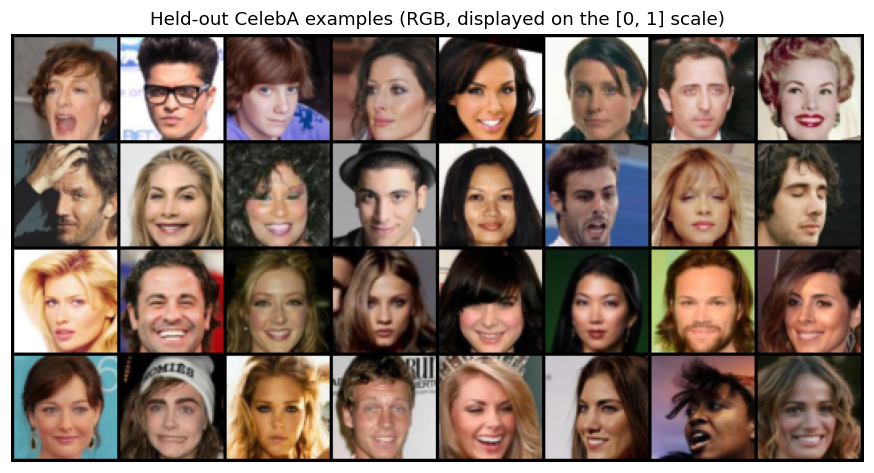

In [6]:
def to_display(images):
    # A fixed intensity scale for every image. This never modifies the sampler's tensors.
    return ((images.detach().cpu() + 1) / 2).clamp(0, 1)


def show_faces(images, title, nrow=8, filename=None):
    grid = make_grid(to_display(images), nrow=nrow, padding=2, pad_value=0)
    fig, ax = plt.subplots(figsize=(min(10, nrow * 1.1), max(2, math.ceil(len(images)/nrow)*1.1)))
    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set(title=title)
    ax.axis('off')
    fig.tight_layout()
    if filename is not None:
        fig.savefig(filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def show_trajectories(states, steps, title, prefix=None, rows_per_figure=4):
    """states: (number of saved times, number of images, 3, H, W). Every image gets a row."""
    assert states.ndim == 5 and len(states) == len(steps)
    images = to_display(states)
    n_images = states.shape[1]
    for start in range(0, n_images, rows_per_figure):
        end = min(start + rows_per_figure, n_images)
        fig, axes = plt.subplots(end-start, len(steps), squeeze=False,
                                 figsize=(1.4*len(steps), 1.45*(end-start)+0.65))
        for row, sample_id in enumerate(range(start, end)):
            for col, step in enumerate(steps):
                ax = axes[row, col]
                ax.imshow(images[col, sample_id].permute(1, 2, 0).numpy())
                ax.set_xticks([]); ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
                if row == 0:
                    ax.set_title(f't = {step}')
                if col == 0:
                    ax.set_ylabel(f'Image {sample_id+1}')
        fig.suptitle(title, y=1.01)
        fig.tight_layout()
        if prefix is not None:
            fig.savefig(f'{prefix}_{start+1:02d}-{end:02d}.png', dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)


show_faces(torch.stack([val_data[i][0] for i in range(min(32, len(val_data)))]),
            'Held-out CelebA examples (RGB, displayed on the [0, 1] scale)',
            filename=RUN_DIR / 'data_examples.png')

## 3. Forward diffusion and the noise schedule

We use **mathematical timestep labels throughout the code**: $x_0$ is clean, and
$t=1,\ldots,T$ are noisy states. Schedule arrays have length $T+1$, with a dummy entry
$\beta_0=0$ and $\bar\alpha_0=1$. Thus `states[0]` in a returned trajectory is its first
saved state, whereas `steps[0]` tells you that state's actual diffusion time.

For $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$,
$$
x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,
\qquad \epsilon\sim\mathcal N(0,I_{12288}).
$$
One direct draw is enough for training; we do not simulate all earlier forward steps.
`extract` turns a batch of timestep indices into coefficients of shape `(B,1,1,1)` so
PyTorch can broadcast them across image channels and pixels.

Here an image has $D=3\cdot64\cdot64=12288$ scalar coordinates.

In [7]:
class DiffusionSchedule(nn.Module):
    def __init__(self, steps=1000, beta_start=1e-4, beta_end=0.02):
        super().__init__()
        self.steps = steps
        # Compute coefficients in float64, then store float32 for model calculations.
        beta = torch.cat([torch.zeros(1, dtype=torch.float64),
                          torch.linspace(beta_start, beta_end, steps, dtype=torch.float64)])
        alpha = 1 - beta
        alpha_bar = alpha.cumprod(dim=0)
        alpha_bar_prev = torch.cat([torch.ones(1, dtype=torch.float64), alpha_bar[:-1]])
        denominator = (1 - alpha_bar).clamp_min(1e-20)
        values = {
            'beta': beta, 'alpha': alpha, 'alpha_bar': alpha_bar,
            'sqrt_alpha_bar': alpha_bar.sqrt(),
            'sqrt_one_minus_alpha_bar': (1 - alpha_bar).sqrt(),
            'posterior_variance': beta * (1 - alpha_bar_prev) / denominator,
            'posterior_coef_x0': beta * alpha_bar_prev.sqrt() / denominator,
            'posterior_coef_xt': alpha.sqrt() * (1 - alpha_bar_prev) / denominator,
        }
        for name, value in values.items():
            self.register_buffer(name, value.float())

    def extract(self, name, t):
        return getattr(self, name)[t].view(-1, 1, 1, 1)

    def q_sample(self, x0, t, noise=None):
        if noise is None:
            noise = torch.randn_like(x0)
        return (self.extract('sqrt_alpha_bar', t) * x0
                + self.extract('sqrt_one_minus_alpha_bar', t) * noise)


diffusion = DiffusionSchedule(T, BETA_START, BETA_END).to(device)
print(f'alpha_bar[T] = {diffusion.alpha_bar[-1].item():.6g}')
print(f'Remaining signal coefficient = {diffusion.sqrt_alpha_bar[-1].item():.6g}')


alpha_bar[T] = 4.03583e-05
Remaining signal coefficient = 0.00635282


The next figure illustrates the forward marginals using the **same noise draw** at different
timesteps to make the progression easy to see. These are not consecutive states of a sampled
forward Markov chain. The generation figure later records a genuine reverse sampling trajectory.


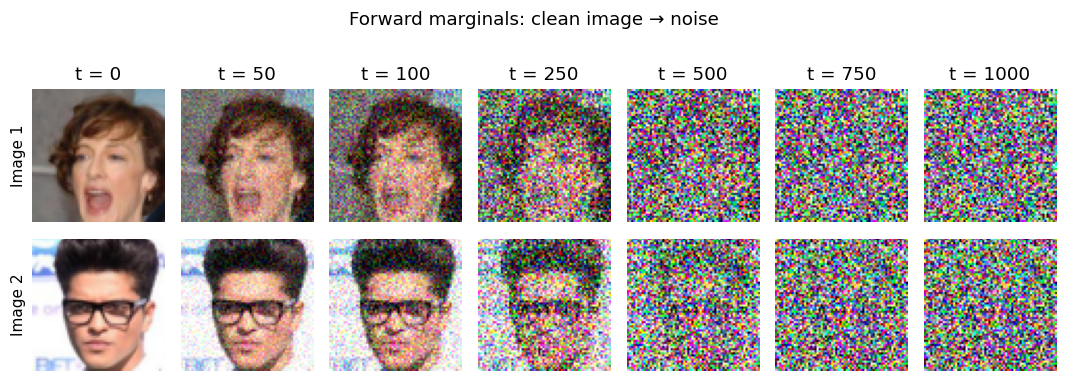

In [8]:
forward_steps = sorted(set([0, T//20, T//10, T//4, T//2, 3*T//4, T]))
x0_examples = torch.stack([val_data[i][0] for i in range(2)]).to(device)
noise = torch.randn(x0_examples.shape, generator=torch.Generator().manual_seed(SEED+1)).to(device)
with torch.inference_mode():
    forward_states = torch.stack([
        diffusion.q_sample(x0_examples, torch.full((2,), t, device=device, dtype=torch.long), noise).cpu()
        for t in forward_steps
    ])
show_trajectories(forward_states, forward_steps, 'Forward marginals: clean image → noise',
                  prefix=RUN_DIR / 'forward')


## 4. Four-level, attention-free residual U-Net

The model implements $\epsilon_\theta(x_t,t)$ and predicts noise with shape `(B, 3, 64, 64)`.
Its output is unrestricted: **there is no sigmoid or tanh output activation**.
Compared with the MNIST lab, this adds one complete encoder/decoder resolution level,
including its skip connection, and uses wider layers for RGB face images.

| Stage | Feature shape, excluding batch | Operations |
|:--|:--|:--|
| Input stem | 64 × 64 × 64 | 3 × 3 convolution, RGB → 64 channels |
| Encoder level 1 | 64 × 64 × 64 | 2 residual blocks; save skip |
| Downsample | 128 × 32 × 32 | 3 × 3 convolution, stride 2, padding 1 |
| Encoder level 2 | 128 × 32 × 32 | 2 residual blocks; save skip |
| Downsample | 256 × 16 × 16 | 3 × 3 convolution, stride 2, padding 1 |
| Encoder level 3 | 256 × 16 × 16 | 2 residual blocks; save skip |
| Downsample | 256 × 8 × 8 | 3 × 3 convolution, stride 2, padding 1 |
| Bottleneck | 256 × 8 × 8 | 2 residual blocks |
| Decoder level 3 | 256 × 16 × 16 | Upsample; concatenate skip → 512 channels; 2 residual blocks |
| Decoder level 2 | 128 × 32 × 32 | Upsample; concatenate skip → 256 channels; 2 residual blocks |
| Decoder level 1 | 64 × 64 × 64 | Upsample; concatenate skip → 128 channels; 2 residual blocks |
| Output | 3 × 64 × 64 | GroupNorm, SiLU, 3 × 3 convolution |

The table uses `BASE_CHANNELS=64`; widths scale with that setting. There are **14 residual blocks**:
6 in the encoder, 2 in the bottleneck, and 6 in the decoder. Upsampling is nearest-neighbor resizing
followed by a 3 × 3 convolution. All convolutions use 3 × 3 kernels except the 1 × 1 residual projections.

**Two kinds of skip connection.** U-Net skips concatenate encoder and decoder features along the
channel dimension. Inside a residual block, a short connection adds the input to the block's result
(after a 1 × 1 projection when its channel count changes).

**Residual block.** GroupNorm → SiLU → 3 × 3 convolution → add projected time embedding →
GroupNorm → SiLU → dropout → 3 × 3 convolution, then add the residual shortcut.

**Time conditioning.** A fixed 64-dimensional sinusoidal encoding of $t$ passes through a learned
64 → 256 → 256 MLP at the default settings. Every residual block projects that vector to its own
output channels and broadcasts it across spatial positions. All timesteps share one U-Net.

In [9]:
def group_norm(channels):
    groups = next(g for g in (8, 4, 2, 1) if channels % g == 0)
    return nn.GroupNorm(groups, channels)


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim >= 4 and dim % 2 == 0
        half = dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half) / (half - 1))
        self.register_buffer('frequencies', frequencies)

    def forward(self, t):
        angles = t.float()[:, None] * self.frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim, dropout=0.0):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (nn.Identity() if in_channels == out_channels
                     else nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(F.silu(time_embedding))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


In [10]:
class CelebAUNet(nn.Module):
    def __init__(self, base_channels=64, time_dim=256, dropout=0.0):
        super().__init__()
        c = base_channels
        self.image_size = 64
        self.image_channels = 3
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(c), nn.Linear(c, time_dim), nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.stem = nn.Conv2d(3, c, 3, padding=1)

        self.enc64 = nn.ModuleList([ResidualBlock(c, c, time_dim, dropout) for _ in range(2)])
        self.down64 = nn.Conv2d(c, 2*c, 3, stride=2, padding=1)
        self.enc32 = nn.ModuleList([ResidualBlock(2*c, 2*c, time_dim, dropout) for _ in range(2)])
        self.down32 = nn.Conv2d(2*c, 4*c, 3, stride=2, padding=1)
        self.enc16 = nn.ModuleList([ResidualBlock(4*c, 4*c, time_dim, dropout) for _ in range(2)])
        self.down16 = nn.Conv2d(4*c, 4*c, 3, stride=2, padding=1)
        self.middle = nn.ModuleList([ResidualBlock(4*c, 4*c, time_dim, dropout) for _ in range(2)])

        self.up16 = nn.Conv2d(4*c, 4*c, 3, padding=1)
        self.dec16 = nn.ModuleList([
            ResidualBlock(8*c, 4*c, time_dim, dropout),
            ResidualBlock(4*c, 4*c, time_dim, dropout),
        ])
        self.up32 = nn.Conv2d(4*c, 2*c, 3, padding=1)
        self.dec32 = nn.ModuleList([
            ResidualBlock(4*c, 2*c, time_dim, dropout),
            ResidualBlock(2*c, 2*c, time_dim, dropout),
        ])
        self.up64 = nn.Conv2d(2*c, c, 3, padding=1)
        self.dec64 = nn.ModuleList([
            ResidualBlock(2*c, c, time_dim, dropout),
            ResidualBlock(c, c, time_dim, dropout),
        ])
        self.output = nn.Sequential(group_norm(c), nn.SiLU(), nn.Conv2d(c, 3, 3, padding=1))
        nn.init.zeros_(self.output[-1].weight)
        nn.init.zeros_(self.output[-1].bias)

    @staticmethod
    def apply_blocks(blocks, x, embedding):
        for block in blocks:
            x = block(x, embedding)
        return x

    def forward(self, x, t):
        embedding = self.time_mlp(t)
        skip64 = self.apply_blocks(self.enc64, self.stem(x), embedding)
        skip32 = self.apply_blocks(self.enc32, self.down64(skip64), embedding)
        skip16 = self.apply_blocks(self.enc16, self.down32(skip32), embedding)
        h = self.apply_blocks(self.middle, self.down16(skip16), embedding)

        h = self.up16(F.interpolate(h, size=skip16.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec16, torch.cat([h, skip16], dim=1), embedding)
        h = self.up32(F.interpolate(h, size=skip32.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec32, torch.cat([h, skip32], dim=1), embedding)
        h = self.up64(F.interpolate(h, size=skip64.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec64, torch.cat([h, skip64], dim=1), embedding)
        return self.output(h)

In [11]:
seed_everything(SEED)
model = CelebAUNet(BASE_CHANNELS, TIME_DIM, DROPOUT).to(device)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)

model.eval()
with torch.inference_mode():
    dummy_x = torch.randn(2, IMAGE_CHANNELS, IMAGE_SIZE, IMAGE_SIZE, device=device)
    dummy_t = torch.tensor([1, T], dtype=torch.long, device=device)
    dummy_output = model(dummy_x, dummy_t)
assert dummy_output.shape == dummy_x.shape
assert torch.isfinite(dummy_output).all()
print('Input/output:', tuple(dummy_output.shape))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')
print('Residual blocks:', sum(isinstance(m, ResidualBlock) for m in model.modules()))
print('Attention modules: 0')
del dummy_x, dummy_t, dummy_output

Input/output: (2, 3, 64, 64)
Trainable parameters: 12,110,019
Residual blocks: 14
Attention modules: 0


## 5. Minibatch training objective and EMA

For every image in a minibatch, independently draw $t_i\sim\mathrm{Uniform}\{1,\ldots,T\}$
and $\epsilon_i\sim\mathcal N(0,I_{12288})$, then construct $x_{t_i}$ directly. The loss is
$$
\widehat{\mathcal L}_{\mathrm{simple}}(\theta)
=\frac{1}{B\cdot12288}\sum_{i=1}^{B}
\left\|\epsilon_i-\epsilon_\theta(x_{t_i},t_i)\right\|_2^2.
$$
`F.mse_loss` averages over the batch and pixels. Compared with the usual squared-norm
expression, this introduces only the constant factor $1/12288$.

`model.train()` enables dropout if requested; `model.eval()` disables it during evaluation
and generation. EMA maintains a smoothed parameter copy for evaluation and sampling, using
$\theta_{\rm EMA}\leftarrow d\theta_{\rm EMA}+(1-d)\theta$ after each optimizer step. A short
warm-up of $d$ prevents the EMA from retaining too much of the initialization early in training.

The EMA maximum decay remains 0.999 with a short warm-up, matching the MNIST lab. This is a
teaching configuration rather than a reproduction of the original paper's 0.9999 EMA setting.
With CUDA gradient scaling, EMA updates only when an optimizer update actually occurs.

In [12]:
def model_autocast(model_device):
    if USE_AMP and model_device.type == 'cuda':
        return torch.autocast(device_type='cuda', dtype=torch.float16)
    return nullcontext()


@torch.no_grad()
def update_ema(ema_model, model, global_step):
    decay = min(EMA_DECAY, (1 + global_step) / (10 + global_step))
    for ema_parameter, parameter in zip(ema_model.parameters(), model.parameters()):
        ema_parameter.lerp_(parameter, 1 - decay)
    for ema_buffer, buffer in zip(ema_model.buffers(), model.buffers()):
        ema_buffer.copy_(buffer)


def train_one_epoch(model, ema_model, loader, optimizer, scaler, diffusion, epoch, global_step):
    model.train()
    model_device = next(model.parameters()).device
    total_loss, count, skipped = 0.0, 0, 0
    starting_step = global_step
    batches = tqdm(loader, desc=f'Epoch {epoch}', leave=False, disable=not SHOW_PROGRESS)
    for x0, _ in batches:                    # Face attributes are intentionally unused.
        x0 = x0.to(model_device, non_blocking=(model_device.type == 'cuda'))
        t = torch.randint(1, diffusion.steps + 1, (len(x0),), device=model_device)
        noise = torch.randn_like(x0)
        xt = diffusion.q_sample(x0, t, noise)
        optimizer.zero_grad(set_to_none=True)
        with model_autocast(model_device):
            predicted_noise = model(xt, t)
            loss = F.mse_loss(predicted_noise.float(), noise)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite loss. Check the data and learning rate.')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP,
                                 error_if_nonfinite=not scaler.is_enabled())
        previous_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= previous_scale:
            global_step += 1
            update_ema(ema_model, model, global_step)
        else:
            skipped += 1                    # Overflow: optimizer and EMA both skip this batch.
        total_loss += loss.detach().item() * len(x0)
        count += len(x0)
        batches.set_postfix(mse=f'{total_loss/count:.4f}', skipped=skipped)
    if global_step == starting_step:
        raise FloatingPointError('No optimizer updates completed. Try USE_AMP=False or a lower learning rate.')
    return total_loss / count, global_step


@torch.inference_mode()
def evaluate_noise_mse(model, loader, diffusion, seed=1001):
    was_training = model.training
    model.eval()
    # Same t/noise at each evaluation; local CPU RNG also works with MPS.
    generator = torch.Generator(device='cpu').manual_seed(seed)
    model_device = next(model.parameters()).device
    total_loss, count = 0.0, 0
    try:
        for x0, _ in loader:
            t = torch.randint(1, diffusion.steps + 1, (len(x0),), generator=generator).to(model_device)
            noise = torch.randn(x0.shape, generator=generator).to(model_device)
            x0 = x0.to(model_device)
            xt = diffusion.q_sample(x0, t, noise)
            with model_autocast(model_device):
                loss = F.mse_loss(model(xt, t).float(), noise)
            total_loss += loss.item() * len(x0)
            count += len(x0)
    finally:
        model.train(was_training)
    result = total_loss / count
    if not math.isfinite(result):
        raise FloatingPointError('Non-finite evaluation loss.')
    return result

## 6. Train and save checkpoints

Choose the checkpoint with the lowest **EMA validation noise-prediction MSE**. This is a
held-out denoising metric, not a direct score of perceptual sample quality. Compare generated
images too. Training loss uses the current model; validation uses the EMA model.

`best_ddpm.pt` stores the selected raw/EMA weights and their configuration. `last_ddpm.pt`
stores the most recent epoch. Set `LOAD_CHECKPOINT` to either file to skip training and generate
from it. Changing the architecture or noise schedule requires a matching checkpoint.


In [13]:
run_config = {
    'architecture': 'celeba_residual_unet_4levels_3x3_v1', 'attention': False,
    'image_size': IMAGE_SIZE, 'image_channels': IMAGE_CHANNELS,
    'channel_multipliers': [1, 2, 4, 4], 'crop_size': 148, 'data_source': DATA_SOURCE, 'input_range': [-1, 1],
    'base_channels': BASE_CHANNELS, 'time_dim': TIME_DIM, 'dropout': DROPOUT,
    'T': T, 'beta_start': BETA_START, 'beta_end': BETA_END,
    'reverse_variance': 'posterior', 'clip_denoised': CLIP_DENOISED,
    'seed': SEED, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    'ema_decay': EMA_DECAY, 'epochs_requested': EPOCHS, 'quick_run': QUICK_RUN,
    'train_size': len(train_data), 'val_size': len(val_data), 'test_size': len(test_data),
    'use_amp': bool(USE_AMP and device.type == 'cuda'),
    'torch_version': str(torch.__version__), 'device': str(device),
}
(RUN_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))


def load_matching_checkpoint(path):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    required = ('architecture', 'image_size', 'image_channels', 'channel_multipliers', 'input_range', 'base_channels', 'time_dim',
                'dropout', 'T', 'beta_start', 'beta_end', 'reverse_variance')
    mismatches = [key for key in required if checkpoint['config'].get(key) != run_config[key]]
    if mismatches:
        raise ValueError(f'Match these settings to the checkpoint, then rerun setup: {mismatches}')
    model.load_state_dict(checkpoint['model_state'])
    ema_model.load_state_dict(checkpoint['ema_state'])
    model.to(device)
    ema_model.to(device).eval()
    return checkpoint


if LOAD_CHECKPOINT is not None:
    best_checkpoint = Path(LOAD_CHECKPOINT)
    checkpoint = load_matching_checkpoint(best_checkpoint)
    history_df = pd.DataFrame(checkpoint['history'])
    print(f'Loaded epoch {checkpoint["epoch"]}; no new training performed.')
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scaler = torch.amp.GradScaler('cuda', enabled=(USE_AMP and device.type == 'cuda'))
    history, global_step = [], 0
    best_val = float('inf')
    best_checkpoint = RUN_DIR / 'best_ddpm.pt'
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        train_mse, global_step = train_one_epoch(
            model, ema_model, train_loader, optimizer, scaler, diffusion, epoch, global_step)
        val_mse = evaluate_noise_mse(ema_model, val_loader, diffusion, seed=1001)
        row = {'epoch': epoch, 'global_step': global_step, 'train_mse': train_mse,
               'val_ema_mse': val_mse, 'seconds': time.perf_counter()-started}
        history.append(row)
        checkpoint = {
            'model_state': model.state_dict(), 'ema_state': ema_model.state_dict(),
            'config': run_config, 'epoch': epoch, 'global_step': global_step,
            'val_ema_mse': val_mse, 'history': list(history),
        }
        if val_mse < best_val:
            best_val = val_mse
            torch.save(checkpoint, best_checkpoint)
        torch.save(checkpoint, RUN_DIR / 'last_ddpm.pt')
        history_df = pd.DataFrame(history)
        history_df.to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'Epoch {epoch:02d}/{EPOCHS} | train MSE {train_mse:.5f}'
              f' | validation EMA MSE {val_mse:.5f} | {row["seconds"]:.1f}s', flush=True)
    print('Best checkpoint:', best_checkpoint.resolve())

history_df.to_csv(RUN_DIR / 'history.csv', index=False)
selected_checkpoint = load_matching_checkpoint(best_checkpoint)
print(f'Selected epoch: {selected_checkpoint["epoch"]}')

Epoch 1:   0%|          | 0/1563 [00:00<?, ?it/s]

Epoch 01/30 | train MSE 0.05068 | validation EMA MSE 0.02182 | 672.0s


Epoch 2:   0%|          | 0/1563 [00:00<?, ?it/s]

Epoch 02/30 | train MSE 0.02138 | validation EMA MSE 0.01992 | 661.6s


Epoch 3:   0%|          | 0/1563 [00:00<?, ?it/s]

...

Epoch 28/30 | train MSE 0.01737 | validation EMA MSE 0.01679 | 672.7s


Epoch 29:   0%|          | 0/1563 [00:00<?, ?it/s]

Epoch 29/30 | train MSE 0.01724 | validation EMA MSE 0.01677 | 658.7s


Epoch 30:   0%|          | 0/1563 [00:00<?, ?it/s]

Epoch 30/30 | train MSE 0.01721 | validation EMA MSE 0.01675 | 669.1s
Best checkpoint: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/celeba_ddpm_20261017_225828_820899/best_ddpm.pt
Selected epoch: 30


## 7. Learning curves and held-out noise prediction

A predictor that always returns zero has expected noise MSE 1. Lower MSE indicates better
noise prediction averaged over timesteps; it does not by itself establish good face generation.
The selected held-out test subset is evaluated only after selecting a checkpoint using validation data.

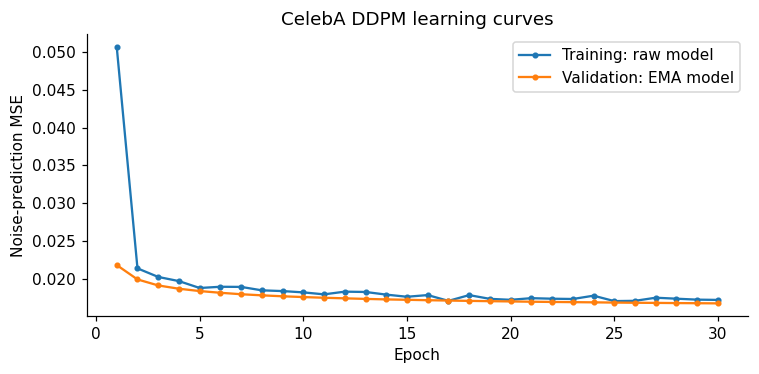

Held-out test noise MSE (EMA): 0.01677


In [14]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history_df['epoch'], history_df['train_mse'], marker='.', label='Training: raw model')
ax.plot(history_df['epoch'], history_df['val_ema_mse'], marker='.', label='Validation: EMA model')
ax.set(xlabel='Epoch', ylabel='Noise-prediction MSE', title='CelebA DDPM learning curves')
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show(); plt.close(fig)

test_mse = evaluate_noise_mse(ema_model, test_loader, diffusion, seed=2002)
test_summary = {'selected_epoch': selected_checkpoint['epoch'], 'test_noise_mse': test_mse,
                'test_size': len(test_data)}
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_summary, indent=2))
print(f'Held-out test noise MSE (EMA): {test_mse:.5f}')

## 8. Reverse diffusion: fresh noise to new faces

Start with $x_T\sim\mathcal N(0,I_{12288})$. At time $t$, predict noise and estimate the clean image:
$$
\widehat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}}.
$$
We optionally clip **this clean-image estimate** to $[-1,1]$, then use the DDPM posterior coefficients:
$$
\mu_\theta(x_t,t)=
\frac{\beta_t\sqrt{\bar\alpha_{t-1}}}{1-\bar\alpha_t}\widehat x_0
+\frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t,
\qquad
\widetilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}.
$$
For $t>1$, sample $x_{t-1}=\mu_\theta(x_t,t)+\sqrt{\widetilde\beta_t}\,z$ with fresh
$z\sim\mathcal N(0,I)$. At **$t=1$, add no noise**. This uses the fixed posterior-variance
choice $\sigma_t^2=\widetilde\beta_t$ discussed in the DDPM paper.

Without clean-estimate clipping, this mean equals the familiar epsilon form
$\alpha_t^{-1/2}\{x_t-\beta_t\epsilon_\theta(x_t,t)/\sqrt{1-\bar\alpha_t}\}$.
The notebook uses all $T$ adjacent reverse steps; saving fewer snapshots does not skip sampling steps.

The recorded columns are actual $x_t$ states from **the same reverse trajectory**. After a step
from $t$ to $t-1$, its result is labeled $t-1$. We preserve the initial pure-noise state and the
final $x_0$. Display clipping affects the figure only; intermediate sampler states stay unclipped.

In [15]:
def default_snapshot_steps(T):
    fractions = [1, 0.8, 0.6, 0.4, 0.2, 0.1, 0.05, 0.02, 0.01, 0]
    return sorted({round(T * fraction) for fraction in fractions}, reverse=True)


@torch.inference_mode()
def sample_ddpm(model, diffusion, n_samples=8, seed=2026, snapshot_steps=None,
                clip_denoised=True, show_progress=True):
    if n_samples < 1:
        raise ValueError('n_samples must be positive.')
    model_device = next(model.parameters()).device
    if diffusion.beta.device != model_device:
        raise ValueError('Move the model and diffusion schedule to the same device.')
    T = diffusion.steps
    steps = default_snapshot_steps(T) if snapshot_steps is None else list(snapshot_steps)
    if any(not isinstance(s, (int, np.integer)) or not 0 <= s <= T for s in steps):
        raise ValueError('Snapshot times must be integers between 0 and T.')
    steps = sorted(set([int(s) for s in steps] + [T, 0]), reverse=True)
    generator = torch.Generator(device='cpu').manual_seed(seed)
    shape = (n_samples, model.image_channels, model.image_size, model.image_size)
    x = torch.randn(shape, generator=generator).to(model_device)   # x_T
    saved = {T: x.cpu().clone()}
    was_training = model.training
    model.eval()
    try:
        for time_step in tqdm(range(T, 0, -1), total=T, desc='DDPM generation',
                              leave=False, disable=not show_progress):
            t = torch.full((n_samples,), time_step, device=model_device, dtype=torch.long)
            with model_autocast(model_device):
                predicted_noise = model(x, t).float()
            x0_hat = ((x - diffusion.extract('sqrt_one_minus_alpha_bar', t) * predicted_noise)
                      / diffusion.extract('sqrt_alpha_bar', t))
            if clip_denoised:
                x0_hat = x0_hat.clamp(-1, 1)
            mean = (diffusion.extract('posterior_coef_x0', t) * x0_hat
                    + diffusion.extract('posterior_coef_xt', t) * x)
            if time_step > 1:
                noise = torch.randn(shape, generator=generator).to(model_device)
                x = mean + diffusion.extract('posterior_variance', t).sqrt() * noise
            else:
                x = mean                                # x_0; no additional noise.
            state_time = time_step - 1
            if state_time in steps:
                saved[state_time] = x.cpu().clone()
        states = torch.stack([saved[t] for t in steps])
        if not torch.isfinite(states).all():
            raise FloatingPointError('Non-finite sampled values. Inspect training and the schedule.')
        return {'samples': x.cpu(), 'states': states, 'steps': steps, 'seed': int(seed)}
    finally:
        model.train(was_training)

## 9. Generate and inspect every face's trajectory

Each row follows one sample through time; the last column matches its final generated image.
The fixed display mapping is `(x + 1) / 2`, clipped to `[0,1]`, so noisy values outside that range
saturate only in the visualization. No per-image contrast normalization is used.

The optional GIF animates the saved snapshots with a longer pause on the final images; frames
are not equally spaced in diffusion time. Raw saved states and their exact timestep labels are
also written to a compressed NumPy file. Change `seed` to generate a new batch; repeating a seed
repeats the initial and subsequent sampling noise on the same setup.

At the default schedule, columns are t = 1000, 800, 600, 400, 200, 100, 50, 20, 10, 0.
The initial state is RGB Gaussian noise, not an encoded or corrupted test image. Figures show
up to four samples per page so every generated face receives its own complete trajectory row.

DDPM generation:   0%|          | 0/1000 [00:00<?, ?it/s]

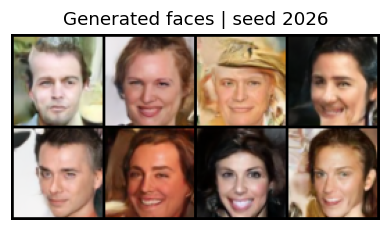

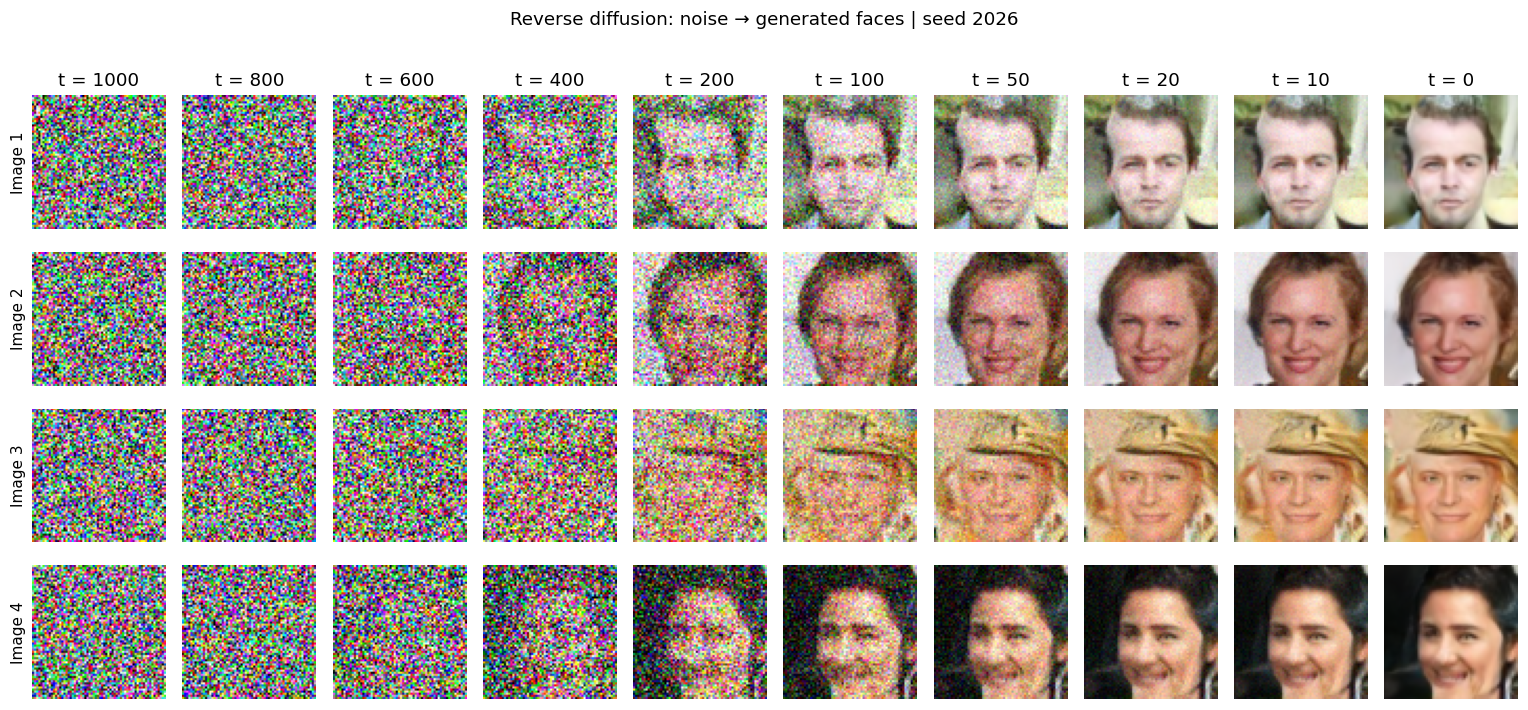

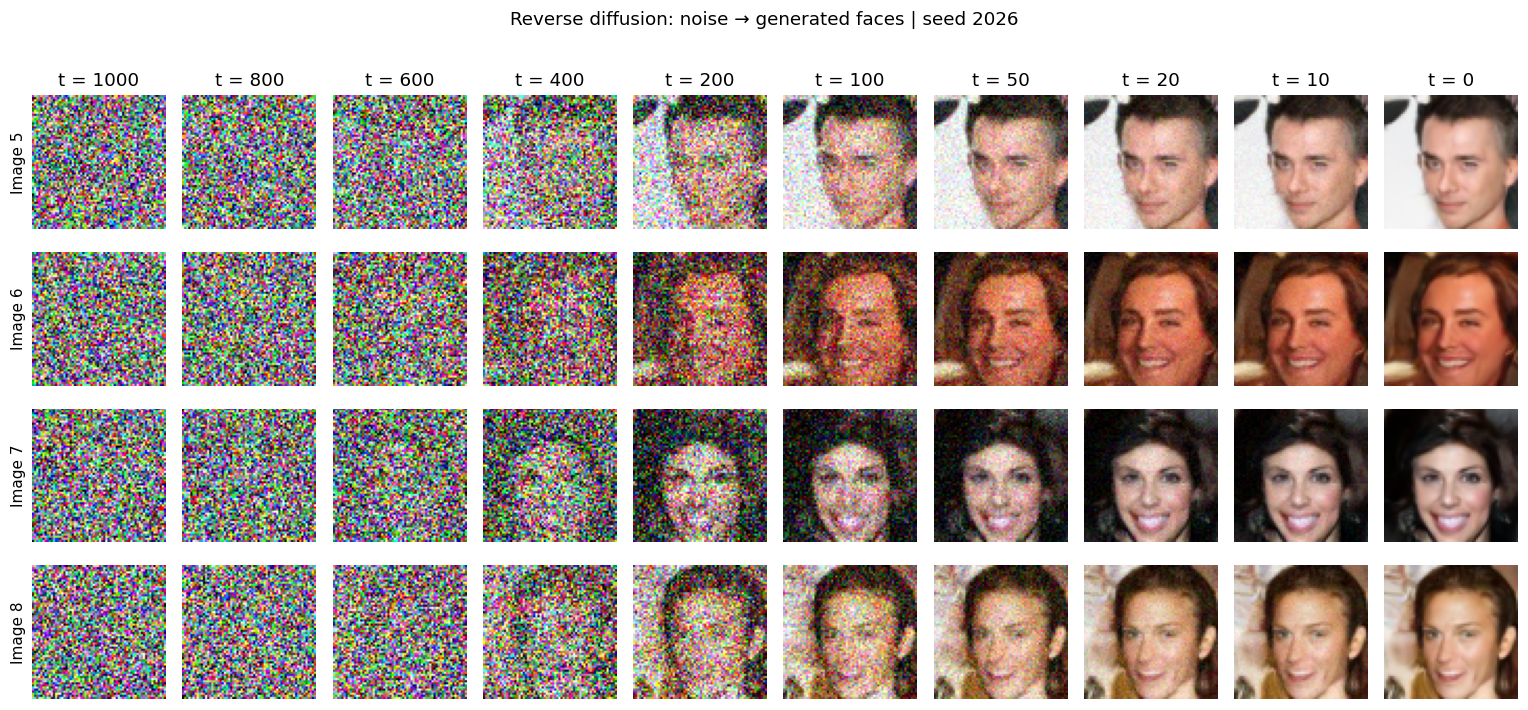

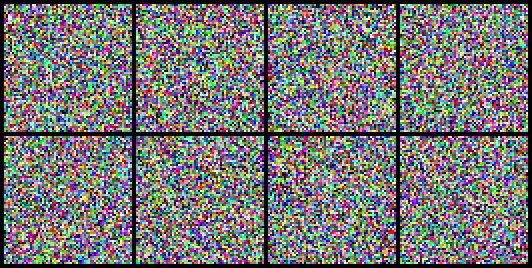

Saved generation: generation_seed2026_120649_268180


In [16]:
def save_trajectory_gif(result, path, nrow=4, scale=2):
    frames = []
    for state in result['states']:
        grid = make_grid(to_display(state), nrow=min(nrow, len(state)), padding=2, pad_value=0)
        array = (grid.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        frame = Image.fromarray(array)
        frame = frame.resize((frame.width * scale, frame.height * scale), resample=Image.Resampling.NEAREST)
        frames.append(frame)
    durations = [300] * len(frames)
    durations[-1] = 1200
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0)


def generate_faces(model, diffusion, n_samples=8, seed=2026, save_gif=True,
                    clip_denoised=True, show_progress=True, snapshot_steps=None):
    result = sample_ddpm(model, diffusion, n_samples=n_samples, seed=seed,
                         clip_denoised=clip_denoised, show_progress=show_progress,
                         snapshot_steps=snapshot_steps)
    tag = f'generation_seed{seed}_{datetime.now():%H%M%S_%f}'
    save_image(to_display(result['samples']), RUN_DIR / f'{tag}_faces.png',
               nrow=min(4, n_samples), padding=2, pad_value=0)
    np.savez_compressed(RUN_DIR / f'{tag}_trajectory.npz',
                        samples=result['samples'].numpy(), states=result['states'].numpy(),
                        steps=np.array(result['steps']), seed=seed)
    show_faces(result['samples'], f'Generated faces | seed {seed}', nrow=min(4, n_samples))
    show_trajectories(result['states'], result['steps'],
                      f'Reverse diffusion: noise → generated faces | seed {seed}',
                      prefix=RUN_DIR / f'{tag}_trajectory')
    if save_gif:
        gif_path = RUN_DIR / f'{tag}.gif'
        save_trajectory_gif(result, gif_path)
        display(DisplayImage(filename=str(gif_path)))
    print('Saved generation:', tag)
    return result


if QUICK_RUN:
    print('Quick-run model: this checks execution, not final face quality.')
generated = generate_faces(
    ema_model, diffusion, n_samples=NUM_GENERATED, seed=SAMPLE_SEED,
    save_gif=SAVE_GIF, clip_denoised=CLIP_DENOISED, show_progress=SHOW_PROGRESS,
)

In [17]:
# Generate another independent batch whenever you like. Every call also shows its trajectories.
# new_batch = generate_faces(ema_model, diffusion, n_samples=8, seed=2027,
#                             save_gif=True, clip_denoised=CLIP_DENOISED)

# Access the raw tensors and timestep labels from the previous call:
print('Final samples:', tuple(generated['samples'].shape))
print('Saved trajectory:', tuple(generated['states'].shape))
print('Saved times:', generated['steps'])
assert generated['steps'][0] == T and generated['steps'][-1] == 0
assert torch.equal(generated['samples'], generated['states'][-1])

Final samples: (8, 3, 64, 64)
Saved trajectory: (10, 8, 3, 64, 64)
Saved times: [1000, 800, 600, 400, 200, 100, 50, 20, 10, 0]


## 10. Reuse trained weights later

The simplest route is to set `LOAD_CHECKPOINT` in the settings cell and rerun the notebook;
the training loop will be skipped. The helper below also rebuilds the model and schedule directly
from a checkpoint's metadata. For a generation-only session, run the setup/import, model,
schedule, plotting, and sampling definitions, then use this helper; no CelebA download is needed.

The model and schedule are rebuilt from checkpoint metadata. These checkpoints are specific to
the four-level RGB model; MNIST checkpoints and checkpoints with another width are not interchangeable.

In [18]:
def load_trained_ddpm(path, target_device=device):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    config = checkpoint['config']
    if (config.get('architecture') != 'celeba_residual_unet_4levels_3x3_v1'
            or config['image_size'] != 64 or config.get('image_channels') != 3):
        raise ValueError('This helper expects a 64×64 RGB CelebA U-Net from this notebook.')
    restored_model = CelebAUNet(config['base_channels'], config['time_dim'], config['dropout'])
    restored_model.load_state_dict(checkpoint['ema_state'])
    restored_model = restored_model.to(target_device).eval().requires_grad_(False)
    restored_diffusion = DiffusionSchedule(config['T'], config['beta_start'], config['beta_end'])
    return restored_model, restored_diffusion.to(target_device), config


# Example (uncomment and replace the path):
# restored_model, restored_diffusion, saved_config = load_trained_ddpm('outputs/.../best_ddpm.pt')
# restored_samples = generate_faces(restored_model, restored_diffusion, n_samples=8, seed=2028,
#                                    clip_denoised=saved_config['clip_denoised'])

## Lab notes and useful experiments

- **Training versus generation:** sample one random timestep per image in training; evaluate all
  1,000 adjacent reverse steps in generation. Saving ten snapshots does not shorten that chain.
- **One additional level:** the MNIST model has two downsampling stages and ten residual blocks.
  This model has three downsampling stages and fourteen residual blocks, with symmetric U-Net skips.
- **Noise prediction:** the target is Gaussian noise with three channels, not a face attribute or
  the original clean image. `t` tells the U-Net which corruption level it is removing.
- **If faces are weak:** first check `QUICK_RUN=False`, correct RGB normalization, and a matching
  checkpoint. Compare fixed-seed samples across longer training runs. Validation noise MSE is not FID
  and does not guarantee perceptual quality. Thirty epochs on a subset is only a starting budget.
- **If memory is limited:** reduce `BATCH_SIZE` or use `BASE_CHANNELS=32`. Changing the width requires
  a new model. CUDA mixed precision reduces activation memory; CPU support does not imply fast training.
- **Data reuse:** point the folder loader at the same extracted images used in the VAE lab. A subset
  reduces training work, but does not reduce the initial archive download. Use the official partitions
  when available; the fallback split is by image, not identity.
- **Controlled comparisons:** fix data subsets, sampling seeds, and training budget when comparing
  widths 32 and 64. Results can still differ across hardware or library versions.
- **Saved outputs:** `config.json`, `history.csv`, `learning_curves.png`, `test_metrics.json`,
  `best_ddpm.pt`, `last_ddpm.pt`, RGB sample grids, trajectory pages, compressed raw states, and GIFs.
  The best checkpoint is selected by validation EMA MSE; the last checkpoint records the final epoch.

### References

- Ho, Jain, and Abbeel (2020), [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239).
- [Authors' diffusion implementation](https://github.com/hojonathanho/diffusion).
- [CelebA project](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html) and
  [torchvision CelebA documentation](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CelebA.html).
- [PyTorch automatic mixed precision](https://docs.pytorch.org/docs/stable/amp.html).

This is an attention-free teaching implementation; it does not reproduce the paper's full model
or reported benchmarks. The supplied VAE notebook guides the CelebA data setup, and the MNIST DDPM
notebook supplies the diffusion, training, and visualization workflow.